# visualize results (segmentation mask)

In [1]:
# set date
date = "2023-06-06-1800"

param_tag = "anvil_detectthres225_seg241_cell_detectthres10_seg10"
def inputpath(model):
    return f"../output/apply_seg/apply_{model}_with_mask_from_nbook/combi_mask/mask_combi_{param_tag}_{date}.nc"

obspath = inputpath("ICON")
iconpath = inputpath("OBS")

### somehow tb need to be loaded here otherwise hdf error

In [2]:
# load tools
import sys 
sys.path.append("../tools")
import handle_OBS_data
import plots_mapping
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import seaborn as sns

import os

In [3]:
from defs_application import georegions

## import package 

In [4]:
import xarray as xr
import pandas as pd
from pathlib import Path
import seaborn as sns
from matplotlib.colors import ListedColormap

 


In [5]:
# diir where to save plots
plot_dir=Path("../output/plots")
if not plot_dir.is_dir():
    plot_dir.mkdir()

# OBS

###  Load data

In [6]:

# load detection
# load segmentation mask
segmentation_mask  = xr.open_dataset(obspath)
# convert to xarray

#convert to xarray
seg2d_cell_filtered  = segmentation_mask["segmentation_mask_cell_filtered"].squeeze()
seg2d_anvil_filtered = segmentation_mask["segmentation_mask_anvil_filtered"].squeeze()

# all
seg2d_cell  = segmentation_mask["segmentation_mask_cell"].squeeze()
seg2d_anvil = segmentation_mask["segmentation_mask_anvil"].squeeze()



# bg layer where all pixels that represent a deselected cell are assigned same value=> so they appear the same grey
seg2d_anvil_bg = seg2d_anvil.where(seg2d_anvil == 0, other=1)
seg2d_cell_bg = seg2d_cell.where(seg2d_cell== 0, other=1)
#seg2d_cell_bg

# cretae colormaps ONCE
cmap_anvil, norm_anvil = plots_mapping.build_id_cmap([seg2d_anvil, seg2d_anvil_filtered], seed=0)
cmap_cell,  norm_cell  = plots_mapping.build_id_cmap([seg2d_cell,  seg2d_cell_filtered],  seed=1)


date_title = plots_mapping.title_time_format(segmentation_mask)



### plot

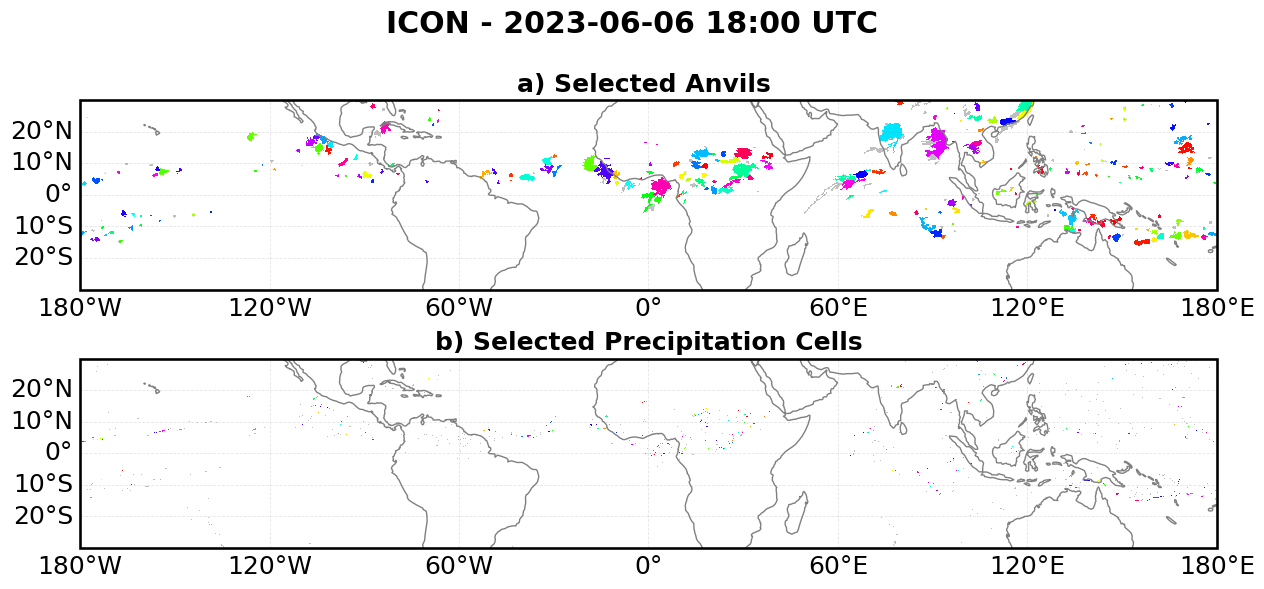

In [7]:

georegion = "global"
#plt.style.use('tex')
sns.set_context("talk")

bg_cmap = ListedColormap([
    (1, 1, 1, 0.0),   # 0 → fully transparent
    (0.75, 0.75, 0.75, 1.0)  # 1 → light grey (darker than before)
])

fig, axes = plt.subplots(
    2, 1,
    figsize=(15, 6),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

fig,axes[0], _ = plots_mapping.domain_plot_seg_mask(seg2d_anvil_filtered,cmap=cmap_anvil,norm = norm_anvil, domain=georegions[georegion], 
                                                            background=seg2d_anvil_bg,cmap_background=bg_cmap,#"Greys",
                                                            title="a) Selected Anvils ", fig=fig, ax=axes[0])
fig,axes[1], _= plots_mapping.domain_plot_seg_mask(seg2d_cell_filtered, cmap=cmap_cell,norm = norm_cell,domain=georegions[georegion],
                                                            background=seg2d_cell_bg,cmap_background=bg_cmap,#"Greys",
                                                            title="b) Selected Precipitation Cells", fig=fig, ax=axes[1])
    

fig.suptitle(f"ICON - {date_title} UTC", fontweight="bold")

plt.tight_layout()
plt.show()
fig.savefig(os.path.join(plot_dir,f"quickplot_seg_output_global_ICON_{date}.pdf"),dpi=150, bbox_inches='tight')

# ICON
### load data 

In [8]:

# load detection
# load segmentation mask
segmentation_mask  = xr.open_dataset(iconpath)
# convert to xarray

#convert to xarray
seg2d_cell_filtered  = segmentation_mask["segmentation_mask_cell_filtered"].squeeze()
seg2d_anvil_filtered = segmentation_mask["segmentation_mask_anvil_filtered"].squeeze()

# all
seg2d_cell  = segmentation_mask["segmentation_mask_cell"].squeeze()
seg2d_anvil = segmentation_mask["segmentation_mask_anvil"].squeeze()



# bg layer where all pixels that represent a deselected cell are assigned same value=> so they appear the same grey
seg2d_anvil_bg = seg2d_anvil.where(seg2d_anvil == 0, other=1)
seg2d_cell_bg = seg2d_cell.where(seg2d_cell== 0, other=1)
#seg2d_cell_bg

# cretae colormaps ONCE
cmap_anvil, norm_anvil = plots_mapping.build_id_cmap([seg2d_anvil, seg2d_anvil_filtered], seed=0)
cmap_cell,  norm_cell  = plots_mapping.build_id_cmap([seg2d_cell,  seg2d_cell_filtered],  seed=1)


date_title = plots_mapping.title_time_format(segmentation_mask)



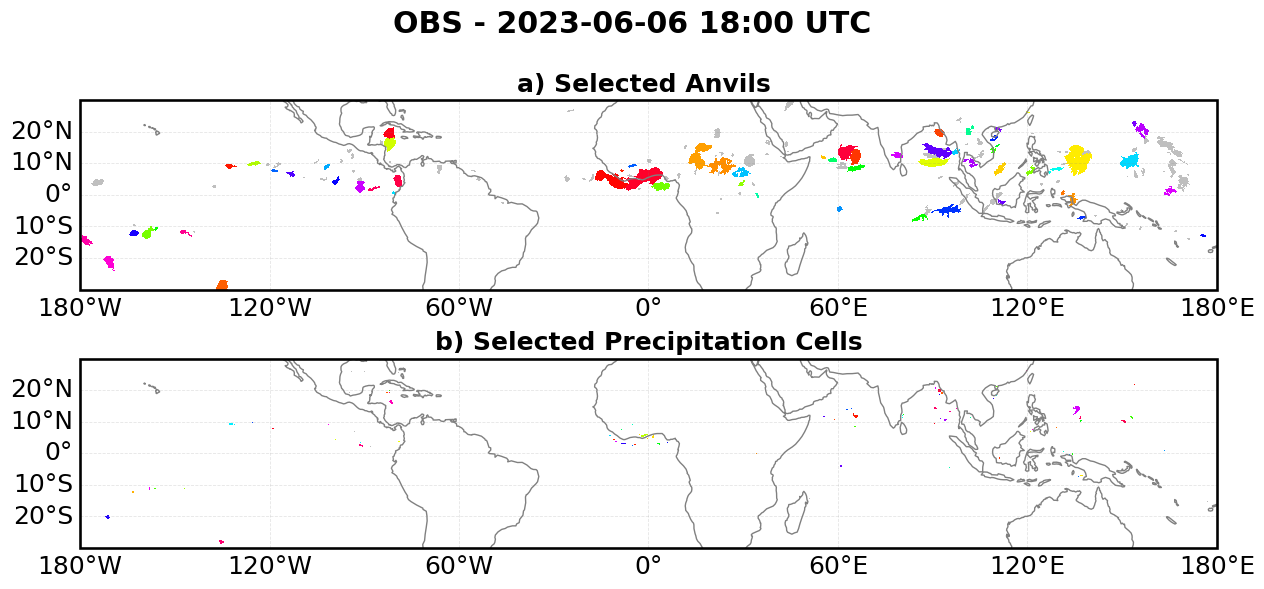

In [9]:

 
georegion = "global"
#plt.style.use('tex')
sns.set_context("talk")


bg_cmap = ListedColormap([
    (1, 1, 1, 0.0),   # 0 → fully transparent
    (0.75, 0.75, 0.75, 1.0)  # 1 → light grey (darker than before)
])


fig, axes = plt.subplots(
    2, 1,
    figsize=(15, 6),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

fig,axes[0], _ = plots_mapping.domain_plot_seg_mask(seg2d_anvil_filtered,cmap=cmap_anvil,norm = norm_anvil, domain=georegions[georegion], 
                                                            background=seg2d_anvil_bg,cmap_background=bg_cmap,#"Greys",
                                                            title="a) Selected Anvils ", fig=fig, ax=axes[0])
fig,axes[1], _= plots_mapping.domain_plot_seg_mask(seg2d_cell_filtered, cmap=cmap_cell,norm = norm_cell,domain=georegions[georegion],
                                                            background=seg2d_cell_bg,cmap_background=bg_cmap,#"Greys",
                                                            title="b) Selected Precipitation Cells", fig=fig, ax=axes[1])
    

fig.suptitle(f"OBS - {date_title} UTC", fontweight="bold")

plt.tight_layout()
plt.show()
fig.savefig(os.path.join(plot_dir,f"quickplot_seg_output_global_OBS_{date}.pdf"),dpi=150, bbox_inches='tight')